/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 62s 32ms/step - accuracy: 0.9604 - loss: 0.1306 - val_accuracy: 0.9850 - val_loss: 0.0479
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 53s 28ms/step - accuracy: 0.9866 - loss: 0.0426 - val_accuracy: 0.9896 - val_loss: 0.0341
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 55s 29ms/step - accuracy: 0.9908 - loss: 0.0297 - val_accuracy: 0.9899 - val_loss: 0.0287
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 80s 28ms/step - accuracy: 0.9929 - loss: 0.0216 - val_accuracy: 0.9898 - val_loss: 0.0315
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 53s 28ms/step - accuracy: 0.9947 - loss: 0.0162 - val_accuracy: 0.9896 - val_loss: 0.0387
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9896 - loss: 0.0387
Loss: 0.03867647796869278
Accuracy: 0.9896000027656555


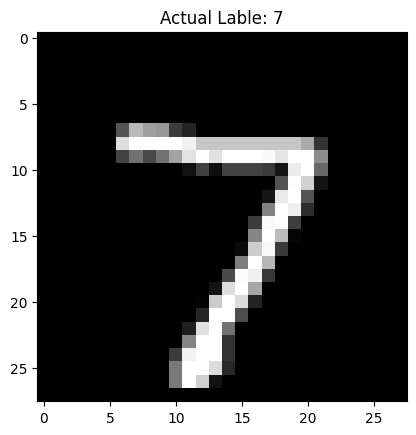

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt

(X_train,y_train),(X_test,y_test)=keras.datasets.mnist.load_data()

X_train = X_train.reshape(-1,28,28,1)/255.0
X_test = X_test.reshape(-1,28,28,1)/255.0

model = keras.Sequential([
    layers.Conv2D(32,(3,3),activation="relu", input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(128,activation="relu"),
    layers.Dense(10,activation="softmax")

])

model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
model.fit(X_train,y_train,epochs=5,validation_data=(X_test,y_test))

loss,acc=model.evaluate(X_test,y_test)

print("Loss:",loss)
print("Accuracy:",acc)

plt.imshow(X_test[0].reshape(28,28),cmap='gray')
plt.title("Actual Lable: "+str(y_test[0]))
plt.show()

pred=model.predict(X_test)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 56s 29ms/step - accuracy: 0.9608 - loss: 0.1279 - val_accuracy: 0.9817 - val_loss: 0.0549
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 53s 28ms/step - accuracy: 0.9871 - loss: 0.0417 - val_accuracy: 0.9875 - val_loss: 0.0385
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 85s 30ms/step - accuracy: 0.9912 - loss: 0.0283 - val_accuracy: 0.9901 - val_loss: 0.0341
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 53s 28ms/step - accuracy: 0.9934 - loss: 0.0204 - val_accuracy: 0.9914 - val_loss: 0.0296
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 53s 28ms/step - accuracy: 0.9956 - loss: 0.0143 - val_accuracy: 0.9886 - val_loss: 0.0324
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9886 - loss: 0.0324
Loss: 0.03240214288234711
Accuracy: 0.9886000156402588
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
Enter actual digit: 3
Correct prediction


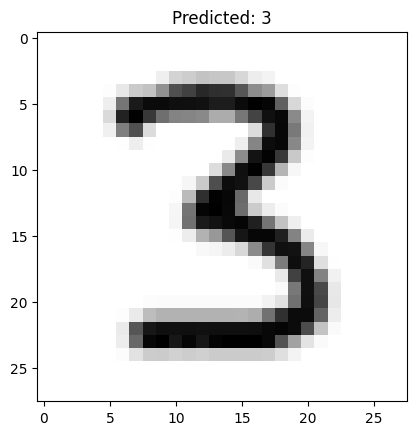

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Redefine and train the MNIST model to ensure it's the correct one
(X_train,y_train),(X_test,y_test)=keras.datasets.mnist.load_data()

X_train = X_train.reshape(-1,28,28,1)/255.0
X_test = X_test.reshape(-1,28,28,1)/255.0

model = keras.Sequential([
    layers.Conv2D(32,(3,3),activation="relu", input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(128,activation="relu"),
    layers.Dense(10,activation="softmax")

])

model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
model.fit(X_train,y_train,epochs=2,validation_data=(X_test,y_test))

loss,acc=model.evaluate(X_test,y_test)

print("Loss:",loss)
print("Accuracy:",acc)

img = Image.open("img1.png").convert("L").resize((28,28))
img = 255 - np.array(img)
# Corrected: Reshape img to (1, 28, 28, 1) for Conv2D input
img = img.reshape(1,28,28,1)/255.0
pred = model.predict(img)
actual = int(input("Enter actual digit: "))
predicted_digit = np.argmax(pred)
if predicted_digit == actual:
  print("Correct prediction")
else:
  print("Wrong Prediction")

plt.imshow(img.reshape(28,28), cmap="gray")
# Corrected: Use predicted_digit variable
plt.title("Predicted: " + str(predicted_digit))
plt.show()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/2
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 69s 43ms/step - accuracy: 0.4626 - loss: 1.4921 - val_accuracy: 0.4968 - val_loss: 1.3585
Epoch 2/2
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 71s 45ms/step - accuracy: 0.6007 - loss: 1.1266 - val_accuracy: 0.6358 - val_loss: 1.0359
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 24ms/step - accuracy: 0.6358 - loss: 1.0359
Loss: 1.035938024520874
Accuracy: 0.6358000040054321


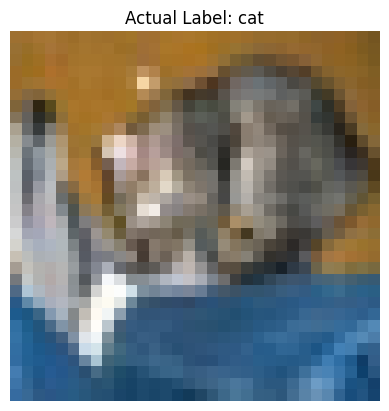

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
Predicted Label: cat


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import cifar10
import numpy as np
import matplotlib.pyplot as plt

(X_train,y_train),(X_test,y_test)=keras.datasets.cifar10.load_data()

X_train = X_train/255.0
X_test = X_test/255.0

model = keras.Sequential([
    layers.Conv2D(32,(3,3),activation="relu", input_shape=(32,32,3)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64,(3,3),activation="relu"),

    layers.Flatten(),

    layers.Dense(128,activation="relu"),
    layers.Dense(10,activation="softmax")

])

model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
model.fit(X_train,y_train,epochs=2,validation_data=(X_test,y_test))

loss,acc=model.evaluate(X_test,y_test)

print("Loss:",loss)
print("Accuracy:",acc)

class_names = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']

plt.imshow(X_test[0])
plt.title("Actual Label: "+class_names[y_test[0][0]])
plt.axis('off')
plt.show()

pred=model.predict(X_test[:1])
print("Predicted Label:", class_names[np.argmax(pred)])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
Predicted Label: bird


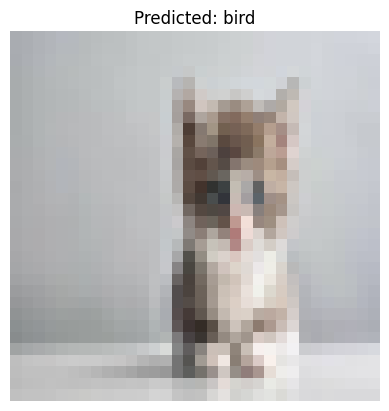

In [ ]:
from PIL import Image


img = Image.open("cat1.png")
img = img.resize((32, 32))
img = np.array(img)
img = img / 255.0

img = img.reshape(1, 32, 32, 3)

pred = model.predict(img)
predicted_class = np.argmax(pred)

print("Predicted Label:", class_names[predicted_class])

plt.imshow(img.reshape(32,32,3))
plt.title("Predicted: " + class_names[predicted_class])
plt.axis('off')
plt.show()